In [9]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
import flash_amr_tools

In [10]:
fig_dir = "/home/watanabe/Projects/meerkat_bowshocks/figures"
flash_output_dir = "/home/watanabe/Projects/meerkat_bowshocks/outputs"

Text(0.5, 1.0, 'Sod MHD test with $\\theta_B = 60^\\circ$')

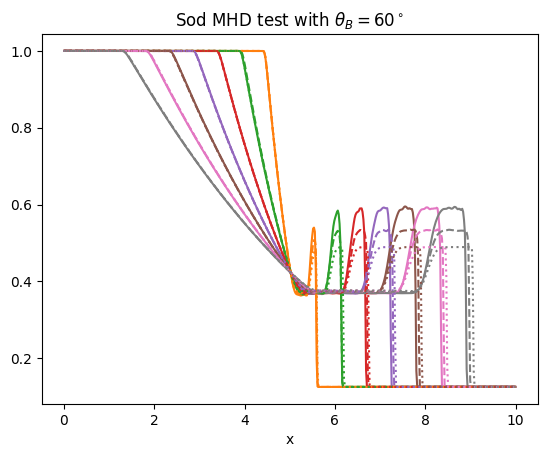

In [11]:
# loop over each file and get the slice
# get list of all files

lss = ["-", "--", ":"]
for im, mgob in enumerate([30,45,60]):
    sim_dir = f"Sod_MHD_mgob{mgob}"
    sim_files = []
    for file in os.listdir(f"{flash_output_dir}/{sim_dir}"):
        if file.find("plt") < 0 or file.find("forced") > 0:
            continue
        sim_files.append(file)

    # sort 
    sim_files = sorted(sim_files)
    for it, sim_file in enumerate(sim_files):
        with h5py.File(f"{flash_output_dir}/{sim_dir}/{sim_file}") as f:
            bbox = f["bounding box"][()]
            node_type = f["node type"][()]

            time = f["real scalars"][()][0][1]
            # print(time)

            # computing cell size
            low_corner = bbox[:,:,0]
            cell_dx = f["block size"][()][:,0] / 8
            cell_dy = f["block size"][()][:,1] / 8
            cell_dz = f["block size"][()][:,2]
            cell_d = np.array((cell_dx,cell_dy,cell_dz))

            # meshgrid of cell sizes
            k,j,i = np.meshgrid(range(1),range(8),range(8), indexing='ij')
            
            # mask to get all leaf nodes (those with max refinement in each block)
            leafmask = node_type == 1

            # x coordinate at lead node
            xcoord = low_corner[leafmask,0,None,None,None] + cell_dx[leafmask,None,None,None]*(.5+i[None,])
            xcoord_arr = np.mean(xcoord, axis=(1,2)).flatten()
            xsorted_idces = np.argsort(xcoord_arr)

            if time > 0:
                plt.plot(xcoord_arr[xsorted_idces], np.mean(f["dens"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces], color=f"C{it}", ls=lss[im])

plt.xlabel("x")
plt.title(rf"Sod MHD test with $\theta_B = {mgob}^\circ$")
# plt.legend(loc="center left")
        # plt.plot(xcoord_arr[xsorted_idces], np.arccos(magx / np.sqrt(magx**2 + magy**2)), color=f"C{it}")

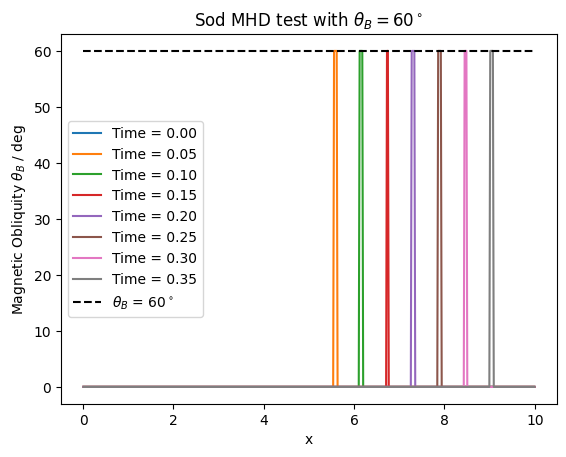

In [12]:
# loop over each file and get the slice
for it, sim_file in enumerate(sim_files):
    with h5py.File(f"{flash_output_dir}/{sim_dir}/{sim_file}") as f:
        bbox = f["bounding box"][()]
        node_type = f["node type"][()]

        time = f["real scalars"][()][0][1]
        # print(time)

        # computing cell size
        low_corner = bbox[:,:,0]
        cell_dx = f["block size"][()][:,0] / 8
        cell_dy = f["block size"][()][:,1] / 8
        cell_dz = f["block size"][()][:,2]
        cell_d = np.array((cell_dx,cell_dy,cell_dz))

        # meshgrid of cell sizes
        k,j,i = np.meshgrid(range(1),range(8),range(8), indexing='ij')
        
        # mask to get all leaf nodes (those with max refinement in each block)
        leafmask = node_type == 1

        # x coordinate at lead node
        xcoord = low_corner[leafmask,0,None,None,None] + cell_dx[leafmask,None,None,None]*(.5+i[None,])
        xcoord_arr = np.mean(xcoord, axis=(1,2)).flatten()
        xsorted_idces = np.argsort(xcoord_arr)

        magy = np.mean(f["magy"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces]
        magx = np.mean(f["magx"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces]

        plt.plot(xcoord_arr[xsorted_idces], np.rad2deg(np.mean(f["mgob"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces]), color=f"C{it}", label=f"Time = {time:.2f}")

plt.hlines(mgob, np.min(xcoord_arr[xsorted_idces]), np.max(xcoord_arr[xsorted_idces]), color="k", ls="--", label=rf"$\theta_B$ = {mgob}$^\circ$")
plt.xlabel("x")
plt.ylabel(r"Magnetic Obliquity $\theta_B$ / deg")
plt.title(rf"Sod MHD test with $\theta_B = {mgob}^\circ$")
plt.legend(loc="center left")
# plt.savefig(f"sod_mhd_mgob{mgob}_check.png")
        # plt.plot(xcoord_arr[xsorted_idces], np.arccos(magx / np.sqrt(magx**2 + magy**2)), color=f"C{it}")

In [13]:
def craccel_mgob(theta_B, theta_crit=np.pi/4, delta_B=np.pi/18):
    '''As in Pais et al 2018'''
    return 0.5 * (np.tanh((theta_crit - theta_B) / delta_B) + 1)

craccel_mach_val = 0.5
# compute CR to thermal ratio, used for calculation of initail resutls
craccel_mgob_val = craccel_mgob(np.deg2rad(mgob))
# print(craccel_mgob_val)
craccel = craccel_mgob_val * craccel_mach_val
print(craccel)

0.0237129365887834


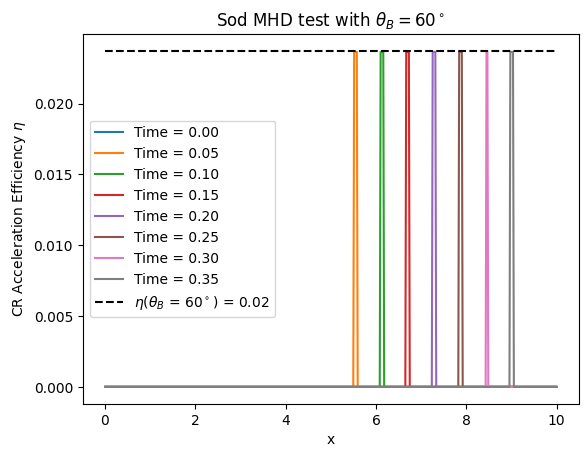

In [14]:
# loop over each file and get the slice
for it, sim_file in enumerate(sim_files):
    with h5py.File(f"{flash_output_dir}/{sim_dir}/{sim_file}") as f:
        bbox = f["bounding box"][()]
        node_type = f["node type"][()]

        time = f["real scalars"][()][0][1]
        # print(time)

        # computing cell size
        low_corner = bbox[:,:,0]
        cell_dx = f["block size"][()][:,0] / 8
        cell_dy = f["block size"][()][:,1] / 8
        cell_dz = f["block size"][()][:,2]
        cell_d = np.array((cell_dx,cell_dy,cell_dz))

        # meshgrid of cell sizes
        k,j,i = np.meshgrid(range(1),range(8),range(8), indexing='ij')
        
        # mask to get all leaf nodes (those with max refinement in each block)
        leafmask = node_type == 1

        # x coordinate at lead node
        xcoord = low_corner[leafmask,0,None,None,None] + cell_dx[leafmask,None,None,None]*(.5+i[None,])
        xcoord_arr = np.mean(xcoord, axis=(1,2)).flatten()
        xsorted_idces = np.argsort(xcoord_arr)

        plt.plot(xcoord_arr[xsorted_idces], np.mean(f["crac"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces], color=f"C{it}", label=f"Time = {time:.2f}")

plt.hlines(craccel, np.min(xcoord_arr[xsorted_idces]), np.max(xcoord_arr[xsorted_idces]), color="k", ls="--", label=rf"$\eta(\theta_B$ = {mgob}$^\circ$) = {craccel:.2f}")
plt.xlabel("x")
plt.ylabel(r"CR Acceleration Efficiency $\eta$")
plt.title(rf"Sod MHD test with $\theta_B = {mgob}^\circ$")
plt.legend(loc="center left")
        # plt.plot(xcoord_arr[xsorted_idces], np.arccos(magx / np.sqrt(magx**2 + magy**2)), color=f"C{it}")

1.7320508075688768e-10


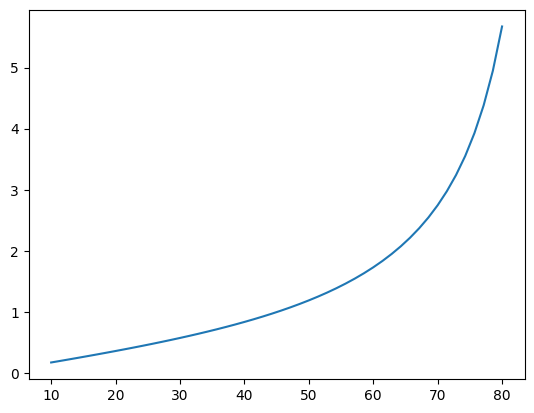

In [15]:
def ByBx(theta_B):
    return np.sqrt(1 / np.cos(np.deg2rad(theta_B))**2 - 1)

thetaBs = np.linspace(10, 80)
plt.plot(thetaBs, ByBx(thetaBs))

print(ByBx(60) * 1e-10)